Jamie Santos
10/11/26
ROB 538
HW 2

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import uniform_filter1d

In [2]:
#########################
# GridWorld Environment #
#########################

class Gridworld:
    def __init__(self, n_agents, reward_func, n_targets=2):
        self.n_agents = n_agents
        self.reward_func = reward_func

        # Static params
        self.dim_1 = 5
        self.dim_2 = 10
        self.goal_positions = [(2,2), (self.dim_1, self.dim_2)][:n_targets]
        self.spawn_point = (3,4)
        
    def reset(self):
        self.agent_positions = [self.spawn_point for _ in range(self.n_agents)]
        self.captured_targets = set()
        return self.get_state()
    
    def step(self, actions):
        # Update positions
        for agent in range(self.n_agents):
            action = actions[agent]
            x, y = self.agent_positions[agent]
            match action:
                case 0:  # Up
                    x = max(1, x - 1)
                case 1:  # Down
                    x = min(self.dim_1, x + 1)
                case 2:  # Left
                    y = max(1, y - 1)
                case 3:  # Right
                    y = min(self.dim_2, y + 1)
                    
            self.agent_positions[agent] = (x, y)
            
        # Check if captured targets
        new_captures = {
            i for i, target in enumerate(self.goal_positions)
            if target in self.agent_positions
            and i not in self.captured_targets
        }
        captures = {
            agent for agent, pos in enumerate(self.agent_positions)
            if any(pos == self.goal_positions[i] for i in new_captures)
        }
        self.captured_targets.update(new_captures)
        
        # Update rewards
        rewards = self.reward_func(self.agent_positions, captures, new_captures)
        done = (len(self.captured_targets) == len(self.goal_positions))
        return self.get_state(), rewards, done

    def get_state(self):
        return (tuple(self.agent_positions), tuple(self.captured_targets))
    
# Define the two different reward functions
def individual_rewards(agent_positions, captures, new_captures):
    rewards = np.full(len(agent_positions), -1)
    for agent in captures:
        rewards[agent] = 20
    return rewards

def global_rewards(agent_positions, captures, new_captures):
    if new_captures:
        team_reward = 20 * len(new_captures)
    else:
        team_reward = -1
    return np.full(len(agent_positions), team_reward)
                

In [3]:
#################
# Training loop #
#################

# Hyperparameters
learning_rate = 0.2
discount_factor = 0.9
epsilon = 0.1
episodes = 5000
max_steps = 100
decay_rate = 0.9999

def run(env, episodes=episodes, learning_rate=learning_rate, discount_factor=discount_factor,
        epsilon=epsilon, max_steps=max_steps, decay_rate=decay_rate, training=True, q_tables=None):
    if q_tables is None:
        q_tables = [{} for _ in range(env.n_agents)] # One table per agent
        
    episode_rewards = []
    trajectories = []
    
    for episode in range(episodes):
        state = env.reset()
        reward_sum = np.zeros(env.n_agents)
        trajectory = [list(env.agent_positions)]
        
        for step in range(max_steps):
            actions = []            

            # Select action for each agent
            for agent in range(env.n_agents):
                if state not in q_tables[agent]:
                    q_tables[agent][state] = np.zeros(4) # Assign 0 for each action
                # Epsilon greedy action selection
                if training and np.random.rand() < epsilon:
                    action = np.random.randint(4)
                else:
                    q_values = q_tables[agent][state]
                    best_actions = np.flatnonzero(q_values == np.max(q_values))
                    #action = int(np.argmax(q_tables[agent][state]))
                    action = np.random.choice(best_actions)
                    
                actions.append(action)
            
            # Environment step
            next_state, rewards, done = env.step(actions)
            
            # Update Q-tables
            for agent in range(env.n_agents):
                if training:
                    if next_state not in q_tables[agent]:
                        q_tables[agent][next_state] = np.zeros(4) # Assign 0 for each action
                    
                    if done:
                        target = rewards[agent]
                    else:
                        target = rewards[agent] + discount_factor * np.max(
                            q_tables[agent][next_state])
                        
                    q_tables[agent][state][actions[agent]] += learning_rate * (target - q_tables[agent][state][actions[agent]])
                reward_sum[agent] += rewards[agent]

            state = next_state
            trajectory.append(list(env.agent_positions))
            
            if done:
                break
            
        episode_rewards.append(reward_sum.copy())
        trajectories.append(trajectory)
        
        if training:
            epsilon = max(0.01, epsilon * decay_rate)  # Decay epsilon
        
    return q_tables, np.array(episode_rewards), trajectories

In [4]:
#####################
# Plot Trajectories #
#####################

def plot_trajectories(env, trajectories, ax=None, title="Trajectories"):
    if ax is None:
        ax = plt.gca()
    ax.set_xlim(0, env.dim_2 )
    ax.set_ylim(0, env.dim_1 )
    ax.set_xticks(range(1, env.dim_2 + 1))
    ax.set_yticks(range(1, env.dim_1 + 1))
    ax.grid(True)
    ax.set_axisbelow(True)
    
    # Targets
    for target, (x, y) in enumerate(env.goal_positions):
        ax.scatter(y - 0.5, x - 0.5, marker='*', s=300, color="crimson", edgecolors="black", zorder=5)
        ax.text(y -0.35, x - 0.35, f"T{target+1}", fontsize=11, color="crimson", weight="bold")
        
    # Trajectories
    for agent in range(env.n_agents):
        x = [pos[agent][0] - 0.5 for pos in trajectories]
        y = [pos[agent][1] - 0.5 for pos in trajectories]
        ax.plot(y, x, marker='o', markersize=5,linewidth=2, label=f"Agent {agent+1}", zorder=3)
        ax.scatter(y[0],x[0], marker="s", s=100, color="green", label=f"Start Agent {agent+1}", zorder=6, edgecolor="black")
    
    ax.set_title(title)
    ax.legend()
    plt.show()

def plot_mega_plot(env, trajectories, title="Trajectories"):
    fix, axes = plt.subplots(1, 5, figsize=(20, 4))
    for i, ax in enumerate(axes):
        plot_trajectories(env, trajectories[i], ax, title=f"{title} - Episode {i+1}")
    plt.tight_layout()
    plt.show()
    
def plot_q_heatmap(env, q_table, agent=0):
    values = np.full((env.dim_1, env.dim_2), np.nan)
    
    for state, q_val in q_table.items():
        pos, captured = state
        x,y = pos[agent]
        values[x-1,y-1] = np.nanmax([
            values[x-1, y-1], np.max(q_val)
        ])
    plt.imshow(values, origin="lower")
    plt.colorbar(label="Max Q-value")
    plt.title("Agent " + str(agent+1) + " Q-vals")
    plt.show()


In [5]:
###################
# Learning Curves #
###################
def plot_learning_curves(rewards_sum, window=1000):
    rewards = np.asarray(rewards_sum)
    
    if rewards.ndim == 1:
        rewards = rewards[:,None]
        
    for agent in range(rewards.shape[1]):
        smoothed = uniform_filter1d(rewards[:, agent], size=window)
        plt.plot(smoothed, label=f"Agent {agent+1}")
    plt.xlabel("Episode")
    plt.ylabel("Total reward")
    plt.title("Learning Curves")
    plt.legend()
    plt.show()

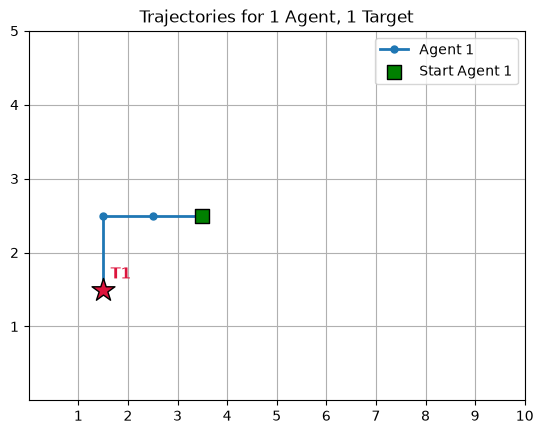

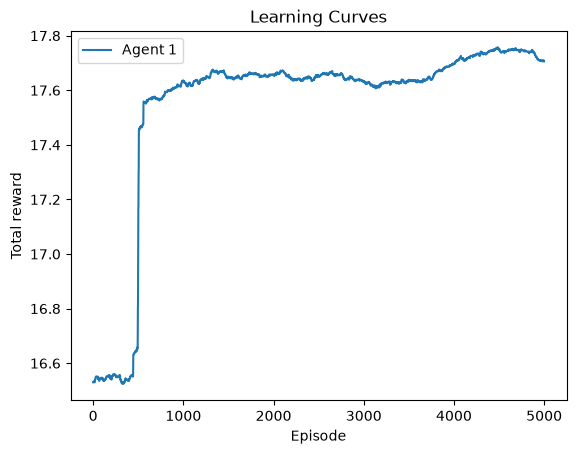

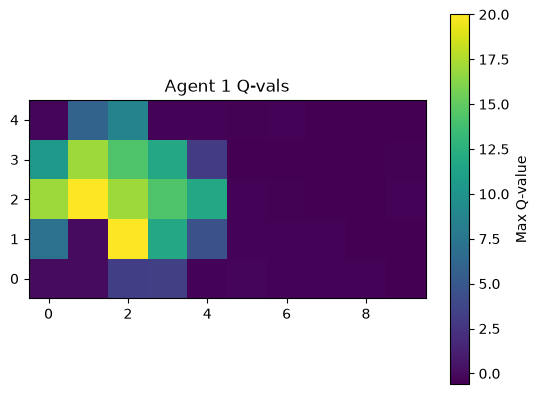

In [6]:
# Question 1: train with 1 agent, 1 target
env1 = Gridworld(n_agents=1, reward_func=individual_rewards, n_targets=1)
q1, r1, trajectories_1 = run(env1, episodes, learning_rate, discount_factor, epsilon, max_steps=100, decay_rate=decay_rate)
q1, eval_rewards_1, eval_traj_1 = run(env1, episodes=5, training=False, q_tables=q1)
plot_trajectories(env1, eval_traj_1[0], title="Trajectories for 1 Agent, 1 Target")
#plot_mega_plot(env1, eval_traj_1)
plot_learning_curves(r1)
plot_q_heatmap(env1, q1[0], agent=0)

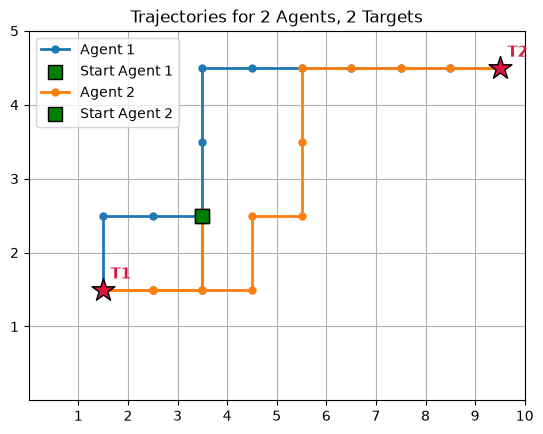

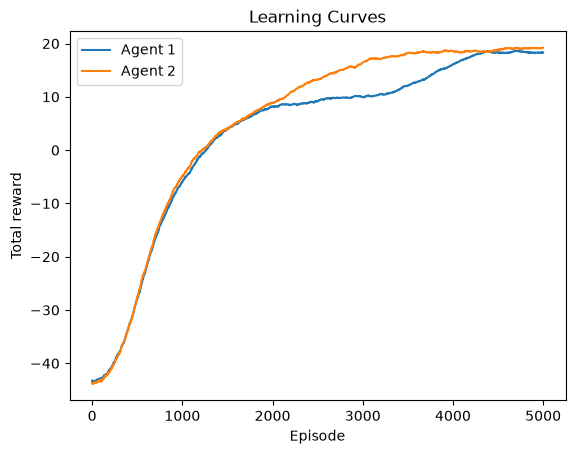

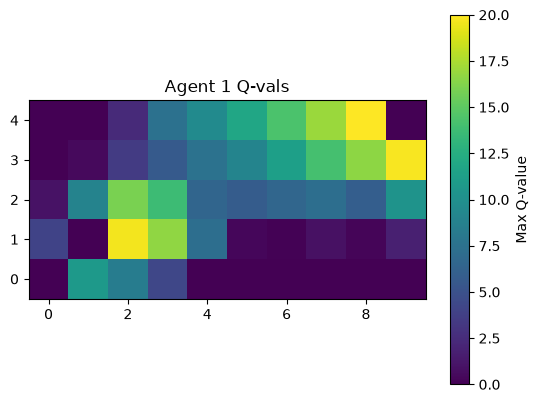

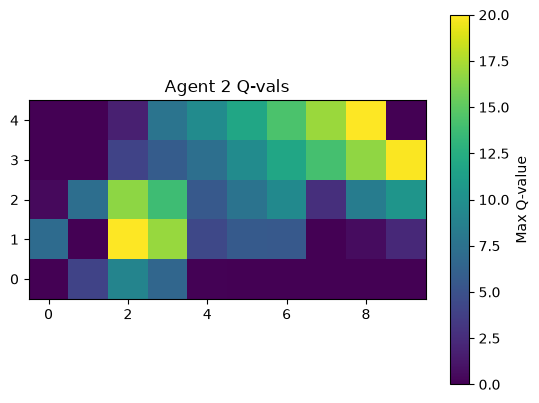

In [7]:
# Question 2: train with 2 agents, 2 targets; individual rewards
env2 = Gridworld(n_agents=2, reward_func=individual_rewards, n_targets=2)
q2, r2, trajectories_2 = run(env2, episodes, learning_rate, discount_factor, epsilon, max_steps=100, decay_rate=decay_rate)
q2, eval_rewards_2, eval_traj_2 = run(env2, episodes=5, training=False, q_tables=q2)
plot_trajectories(env2, eval_traj_2[0], title="Trajectories for 2 Agents, 2 Targets")
#plot_mega_plot(env2, eval_traj_2)
plot_learning_curves(r2)
plot_q_heatmap(env2, q2[0], agent=0)
plot_q_heatmap(env2, q2[1], agent=1)

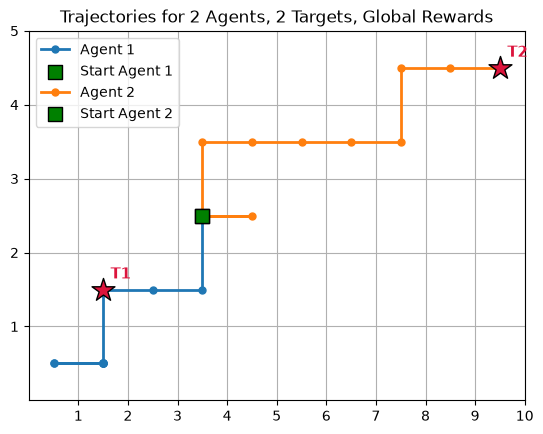

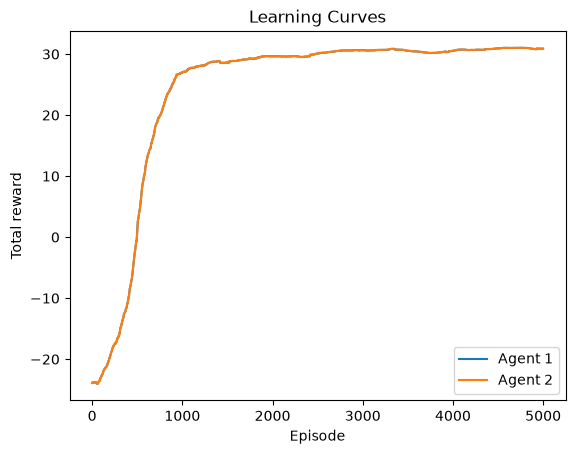

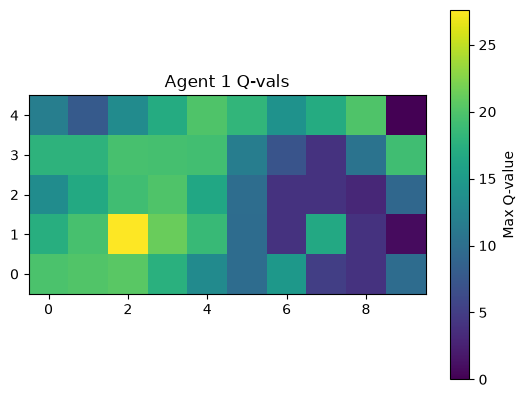

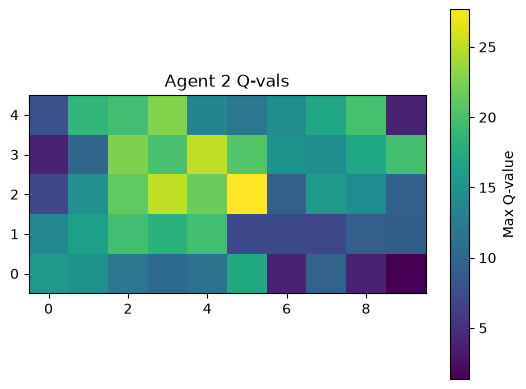

In [8]:
# Question 3: 2 agents, 2 targets; shared rewards
env3 = Gridworld(n_agents=2, reward_func=global_rewards, n_targets=2)
q3, r3, trajectories_3 = run(env3, episodes, learning_rate, discount_factor, epsilon, max_steps=1000, decay_rate=decay_rate)
q3, eval_rewards_3, eval_traj_3 = run(env3, episodes=10, training=False, q_tables=q3)
plot_trajectories(env3, eval_traj_3[0], title="Trajectories for 2 Agents, 2 Targets, Global Rewards")
#plot_mega_plot(env3, eval_traj_3)
plot_learning_curves(r3)
plot_q_heatmap(env3, q3[0], agent=0)
plot_q_heatmap(env3, q3[1], agent=1)